# Actividad 1 - Visualización de datos
## Tiroteos policiales en Estados Unidos (2015)

### Introducción

El Washington Post tiene una base de datos con las personas que murieron por disparos de la policía desde 2015. En esta actividad vamos a analizar solo el año 2015 para responder las preguntas que pide el panel de una organización de derechos humanos.

Archivos que usamos (están en la carpeta `datos`):

- `PoliceKillingsUS4.csv`: una fila por cada persona que murió. Tiene arma, edad, género, raza, ciudad, estado, si tenía señales de enfermedad mental y la fecha.
- `MedianHouseholdIncome2015.csv`: ingreso mediano de los hogares de cada ciudad.
- `ShareRaceByCity2.csv`: porcentaje de cada raza en cada ciudad.
- `population2015.csv`: población de cada estado en 2015.
- `Races.csv`: qué significa cada código de raza.

Los datos fueron modificados por el profesor, así que todos los resultados salen de estos archivos.

## Preparación de datos

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# colores para las gráficas
AZUL = '#1F3A5F'
NARANJA = '#F28C28'
GRIS = '#8C8C8C'

Si el notebook se abre en Google Colab, la carpeta `datos` no existe. En ese caso la siguiente celda pide subir los archivos: se pueden elegir los CSV o el zip de la actividad. En Jupyter normal no hace nada.

In [2]:
import os
import zipfile

if not os.path.exists('datos'):
    from google.colab import files
    os.mkdir('datos')
    subidos = files.upload()
    for nombre in subidos:
        if nombre.endswith('.zip'):
            zipfile.ZipFile(nombre).extractall('datos')
        else:
            os.rename(nombre, 'datos/' + nombre)

print(os.listdir('datos'))

['PercentagePeopleBelowPovertyLevel.csv', 'ShareRaceByCity2.csv', 'Races.csv', 'PercentOver25CompletedHighSchool.csv', 'PoliceKillingsUS4.csv', 'population2015.csv', 'MedianHouseholdIncome2015.csv']


### Lectura de los archivos

En el archivo de muertes el texto `NA` en la columna `race` quiere decir Native American (eso dice `Races.csv`). Pandas normalmente toma `NA` como dato vacío, por eso se usa `keep_default_na=False`.

El archivo de ingresos tiene acentos raros y no abre con la codificación normal, por eso se usa `encoding='latin-1'`.

In [3]:
muertes = pd.read_csv('datos/PoliceKillingsUS4.csv', keep_default_na=False)
ingresos = pd.read_csv('datos/MedianHouseholdIncome2015.csv', encoding='latin-1')
razas_ciudad = pd.read_csv('datos/ShareRaceByCity2.csv')
poblacion = pd.read_csv('datos/population2015.csv')
codigos_raza = pd.read_csv('datos/Races.csv', keep_default_na=False, encoding='utf-8-sig')

print(muertes.shape)
print(ingresos.shape)
print(razas_ciudad.shape)
print(poblacion.shape)

(2535, 15)
(29322, 3)
(29268, 7)
(50, 3)


### Revisión de columnas

In [4]:
muertes.head()

,id,name,manner_of_death,armed,age,gender,race,city,state,State_Name,signs_of_mental_illness,threat_level,flee,body_camera,new_date
0,3,Tim Elliot,shot,gun,53,M,A,Shelton,WA,WASHINGTON,True,attack,Not fleeing,False,01/02/2015
1,4,Lewis Lee Lembke,shot,gun,47,M,W,Aloha,OR,OREGON,False,attack,Not fleeing,False,01/02/2015
2,5,John Paul Quintero,shot and Tasered,unarmed,23,M,H,Wichita,KS,KANSAS,False,other,Not fleeing,False,01/03/2015
3,8,Matthew Hoffman,shot,toy weapon,32,M,W,San Francisco,CA,CALIFORNIA,True,attack,Not fleeing,False,01/04/2015
4,9,Michael Rodriguez,shot,nail gun,39,M,H,Evans,CO,COLORADO,False,attack,Not fleeing,False,01/04/2015


In [5]:
muertes.columns

Index(['id', 'name', 'manner_of_death', 'armed', 'age', 'gender', 'race',
       'city', 'state', 'State_Name', 'signs_of_mental_illness',
       'threat_level', 'flee', 'body_camera', 'new_date'],
      dtype='str')

In [6]:
codigos_raza

,Race ID,Race
0,A,Asian
1,B,Black
2,H,Hispanic
3,N,Not Hispanic
4,NA,Native American
5,O,Unkown
6,W,White


In [7]:
# valores de las columnas que vamos a usar
print(muertes['gender'].value_counts())
print(muertes['race'].value_counts())
print(muertes['signs_of_mental_illness'].value_counts())

gender
M    2428
F     107
Name: count, dtype: int64
race
W     1201
B      618
H      423
NA     195
A       39
N       31
O       28
Name: count, dtype: int64
signs_of_mental_illness
False    1902
True      633
Name: count, dtype: int64


### Limpieza

- La fecha (`new_date`) se pasa a formato fecha para poder sacar el año.
- La edad tiene algunos `NA`. Se pasa a número y esos quedan vacíos.
- En `armed` también hay `NA`, se toman como dato faltante.

In [8]:
muertes['new_date'] = pd.to_datetime(muertes['new_date'], format='%m/%d/%Y')
muertes['anio'] = muertes['new_date'].dt.year

muertes['age'] = pd.to_numeric(muertes['age'], errors='coerce')

muertes['armed'] = muertes['armed'].replace('NA', pd.NA)

# revisar si hay filas repetidas
print('Filas repetidas:', muertes.duplicated().sum())

Filas repetidas: 0


### Filtro del año 2015

In [9]:
print(muertes['anio'].value_counts())

muertes_2015 = muertes[muertes['anio'] == 2015].copy()
print('Muertes en 2015:', len(muertes_2015))

anio
2015    991
2016    963
2017    581
Name: count, dtype: int64
Muertes en 2015: 991


In [10]:
print('Sin edad:', muertes_2015['age'].isna().sum())
print('Sin arma registrada:', muertes_2015['armed'].isna().sum())

Sin edad: 11
Sin arma registrada: 1


En 2015 hay 991 muertes. 11 personas no tienen edad y 1 no tiene arma registrada. No se borran, solo quedan fuera cuando se filtra por edad o se cuentan armas.

## Pregunta 1
### ¿Cuáles son los estados con mayor número de ciudades diferentes donde ocurrieron tiroteos policiales?

Aquí no se cuentan muertes sino ciudades distintas, por eso se usa `nunique()`. Primero se pasan los nombres a minúsculas para no contar dos veces la misma ciudad.

In [11]:
muertes_2015['ciudad'] = muertes_2015['city'].str.lower()

ciudades_estado = muertes_2015.groupby('state')['ciudad'].nunique()
ciudades_estado = ciudades_estado.sort_values(ascending=False)

top10_ciudades = ciudades_estado.head(10)
print(top10_ciudades)

state
CA    114
TX     62
FL     42
GA     27
OK     26
AZ     23
CO     21
OH     20
LA     19
NC     19
Name: ciudad, dtype: int64


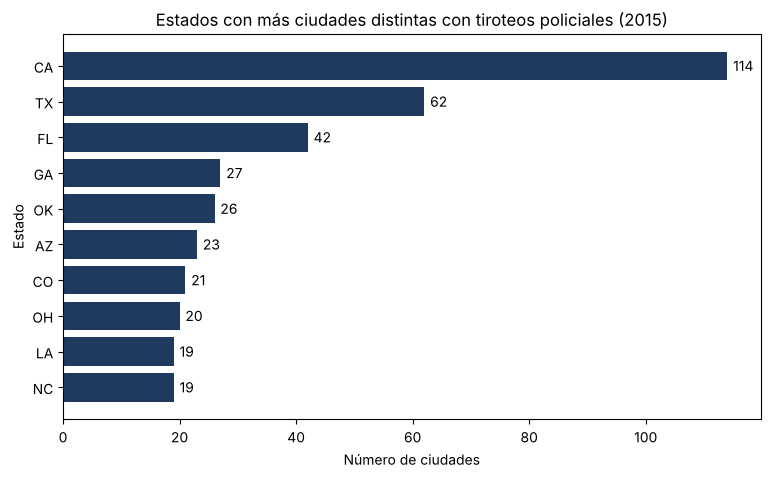

In [12]:
datos = top10_ciudades.sort_values()

plt.figure(figsize=(9, 5))
plt.barh(datos.index, datos.values, color=AZUL)
for i in range(len(datos)):
    plt.text(datos.values[i] + 1, i, datos.values[i], va='center')

plt.title('Estados con más ciudades distintas con tiroteos policiales (2015)')
plt.xlabel('Número de ciudades')
plt.ylabel('Estado')
plt.show()

**Conclusión:** California es el estado con más ciudades distintas con tiroteos: 114. Le siguen Texas con 62 y Florida con 42, así que California tiene casi el doble que Texas. Luego vienen Georgia (27), Oklahoma (26) y Arizona (23). En estos estados los casos no pasaron en una sola ciudad sino en muchas, aunque también hay que tomar en cuenta que son estados grandes con muchas ciudades.

## Pregunta 2
### ¿Cuáles son los niveles de ingreso en los estados con mayor número de muertes de personas que presentaban indicios de enfermedad mental?

Pasos:
1. Quedarse con los casos de 2015 donde `signs_of_mental_illness` es True.
2. Contar por estado y tomar los 10 con más casos.
3. Unir con la tabla de ingresos usando estado y ciudad.
4. Sacar el promedio del ingreso de las ciudades donde hubo casos.

In [13]:
mental = muertes_2015[muertes_2015['signs_of_mental_illness'] == True]
print('Casos con señales de enfermedad mental:', len(mental))

top10_mental = mental['state'].value_counts().head(10)
print(top10_mental)

Casos con señales de enfermedad mental: 254
state
CA    50
TX    24
AZ    12
FL    11
WA     9
AL     8
LA     8
GA     7
OR     7
OK     7
Name: count, dtype: int64


**Arreglar la tabla de ingresos**

- La columna `Median Income` tiene celdas vacías y un valor `250,000+`. El `250,000+` se toma como 250000 y las vacías no se usan.
- En esta tabla las ciudades terminan con una palabra extra (`Los Angeles city`, `Abanda CDP`, `Akron town`). En la tabla de muertes solo dice `Los Angeles`, así que se quita la última palabra y se pasa a minúsculas.
- Al quitar esa palabra algunas ciudades quedan repetidas en el mismo estado (por ejemplo `Salem city` y `Salem CDP`). Para no duplicar casos al unir, se saca el promedio y queda una sola fila por ciudad.

In [14]:
print('Vacías:', ingresos['Median Income'].isna().sum())
print('250,000+:', (ingresos['Median Income'] == '250,000+').sum())

ingresos['ingreso'] = ingresos['Median Income'].replace('250,000+', '250000')
ingresos['ingreso'] = pd.to_numeric(ingresos['ingreso'])

# quitar la última palabra del nombre (city, CDP, town...)
ingresos['ciudad'] = ingresos['City'].str.lower().str.rsplit(' ', n=1).str[0]

ingresos[['Geographic Area', 'City', 'ciudad', 'ingreso']].head()

Vacías: 1913
250,000+: 24


,Geographic Area,City,ciudad,ingreso
0,AL,Abanda CDP,abanda,11207.0
1,AL,Abbeville city,abbeville,25615.0
2,AL,Adamsville city,adamsville,42575.0
3,AL,Addison town,addison,37083.0
4,AL,Akron town,akron,21667.0


In [15]:
ingresos = ingresos.dropna(subset=['ingreso'])
ingresos_ciudad = ingresos.groupby(['Geographic Area', 'ciudad'])['ingreso'].mean().reset_index()
ingresos_ciudad = ingresos_ciudad.rename(columns={'Geographic Area': 'state'})

print('Ciudades con ingreso:', len(ingresos_ciudad))

Ciudades con ingreso: 27326


In [16]:
casos_top10 = mental[mental['state'].isin(top10_mental.index)]
union = pd.merge(casos_top10, ingresos_ciudad, on=['state', 'ciudad'], how='left')

print('Casos antes de unir:', len(casos_top10))
print('Casos después de unir:', len(union))
print('Casos con ingreso:', union['ingreso'].notna().sum())
print('Casos sin ingreso:', union['ingreso'].isna().sum())

Casos antes de unir: 143
Casos después de unir: 143
Casos con ingreso: 126
Casos sin ingreso: 17


In [17]:
# ciudades que no se encontraron en la tabla de ingresos
union[union['ingreso'].isna()][['state', 'city']]

,state,city
17,OR,Colton
31,AL,Lawrence County
37,CA,Wilmington
49,CA,Sylmar
67,GA,Rockville
71,TX,Ellis County
76,TX,Bexar County
81,GA,Augusta
94,CA,San Diego County
97,WA,Hunters


In [18]:
# cada ciudad cuenta una vez aunque tenga varios casos
ciudades_con_ingreso = union.dropna(subset=['ingreso'])
ciudades_con_ingreso = ciudades_con_ingreso.drop_duplicates(subset=['state', 'ciudad'])

ingreso_estado = ciudades_con_ingreso.groupby('state')['ingreso'].mean().round()
num_ciudades = ciudades_con_ingreso.groupby('state')['ingreso'].count()

tabla_q2 = pd.DataFrame({'muertes': top10_mental, 'ingreso_promedio': ingreso_estado, 'ciudades': num_ciudades})
tabla_q2 = tabla_q2.sort_values('muertes', ascending=False)
tabla_q2

,muertes,ingreso_promedio,ciudades
state,,,
CA,50,64445.0,32
TX,24,48834.0,17
AZ,12,47311.0,9
FL,11,47300.0,9
WA,9,53094.0,8
AL,8,45766.0,6
LA,8,41044.0,6
GA,7,50676.0,4
OR,7,51450.0,4


In [19]:
promedio_general = ingresos_ciudad['ingreso'].mean()
print('Promedio de todas las ciudades:', round(promedio_general))

Promedio de todas las ciudades: 51334


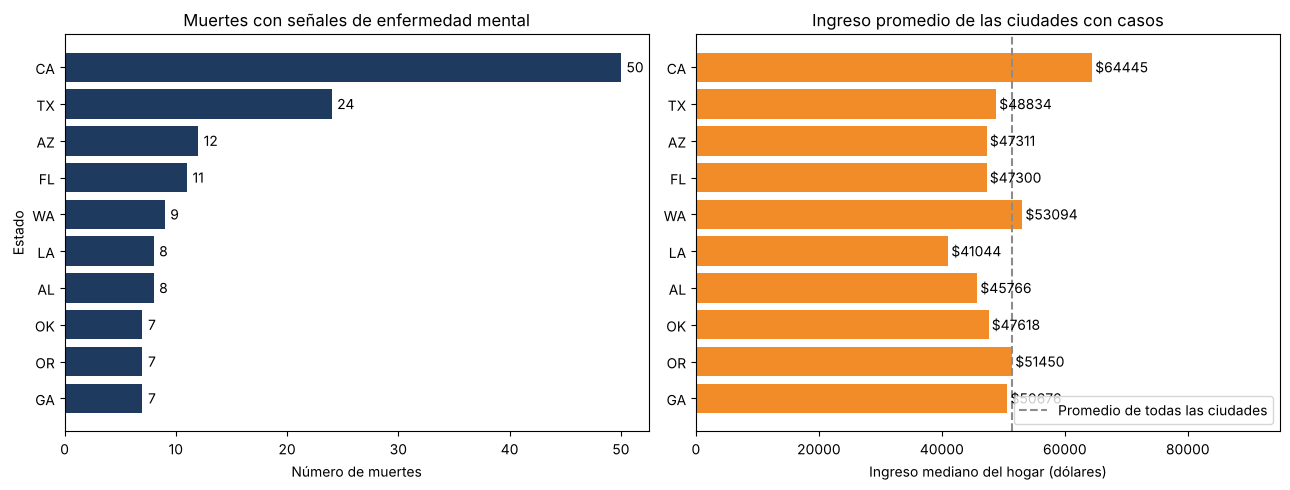

In [20]:
datos = tabla_q2.sort_values('muertes')

plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
plt.barh(datos.index, datos['muertes'], color=AZUL)
for i in range(len(datos)):
    plt.text(datos['muertes'].values[i] + 0.5, i, datos['muertes'].values[i], va='center')
plt.title('Muertes con señales de enfermedad mental')
plt.xlabel('Número de muertes')
plt.ylabel('Estado')

plt.subplot(1, 2, 2)
plt.barh(datos.index, datos['ingreso_promedio'], color=NARANJA)
for i in range(len(datos)):
    plt.text(datos['ingreso_promedio'].values[i] + 500, i, '$' + str(int(datos['ingreso_promedio'].values[i])), va='center')
plt.axvline(promedio_general, color=GRIS, linestyle='--', label='Promedio de todas las ciudades')
plt.title('Ingreso promedio de las ciudades con casos')
plt.xlabel('Ingreso mediano del hogar (dólares)')
plt.xlim(0, 95000)
plt.legend(loc='lower right')

plt.tight_layout()
plt.show()

**Conclusión:** De las 254 muertes con señales de enfermedad mental, California tiene 50 y Texas 24, después vienen Arizona (12) y Florida (11). El ingreso promedio de las ciudades donde pasaron va de $41,044 en Luisiana a $64,445 en California. Solo California, Washington y Oregón quedan arriba del promedio de todas las ciudades ($51,334). California tiene más casos y también el ingreso más alto, entonces no se ve que los estados con más casos sean los más pobres.

Notas: estos ingresos son de ciudades, no es el ingreso oficial del estado. Se pudieron unir 126 de 143 casos (88%). Los que faltan están escritos como condados (Bexar County) o barrios (Sylmar) y no aparecen en la tabla de ingresos. En Georgia solo se encontraron 4 ciudades, así que ese promedio es menos confiable.

## Pregunta 3
### ¿Cuáles fueron las armas más comunes registradas entre las personas fallecidas?

In [21]:
armas = muertes_2015['armed'].value_counts()
print('Casos con arma registrada:', armas.sum())

top10_armas = armas.head(10)
print(top10_armas)

Casos con arma registrada: 990
armed
gun               560
knife             137
unarmed            94
vehicle            55
toy weapon         43
undetermined       27
machete             9
box cutter          7
sword               6
unknown weapon      6
Name: count, dtype: int64


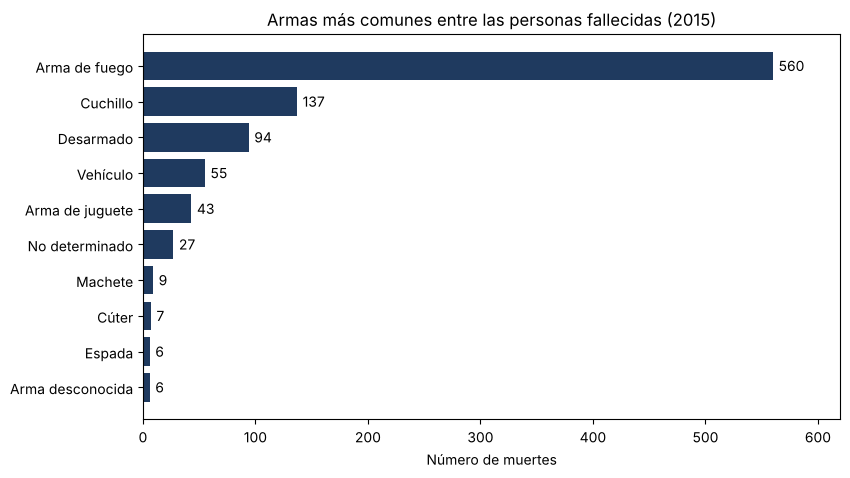

In [22]:
# nombres en español
nombres = {'gun': 'Arma de fuego', 'knife': 'Cuchillo', 'unarmed': 'Desarmado',
           'vehicle': 'Vehículo', 'toy weapon': 'Arma de juguete', 'undetermined': 'No determinado',
           'machete': 'Machete', 'box cutter': 'Cúter', 'sword': 'Espada',
           'unknown weapon': 'Arma desconocida'}

datos = top10_armas.rename(index=nombres).sort_values()

plt.figure(figsize=(9, 5))
plt.barh(datos.index, datos.values, color=AZUL)
for i in range(len(datos)):
    plt.text(datos.values[i] + 5, i, datos.values[i], va='center')

plt.title('Armas más comunes entre las personas fallecidas (2015)')
plt.xlabel('Número de muertes')
plt.xlim(0, 620)
plt.show()

In [23]:
# porcentaje de las 3 primeras
print(round(top10_armas.head(3) / armas.sum() * 100, 1))

armed
gun        56.6
knife      13.8
unarmed     9.5
Name: count, dtype: float64


**Conclusión:** El arma más común es el arma de fuego, con 560 de 990 casos (56.6%). Después está el cuchillo con 137 (13.8%). En tercer lugar están las personas desarmadas, con 94 casos (9.5%), y luego vehículos (55) y armas de juguete (43). Casi 1 de cada 10 personas que murieron no tenía arma.

## Pregunta 4
### ¿En qué estados ocurrieron tiroteos donde las víctimas tenían armas de juguete?

In [24]:
juguete = muertes_2015[muertes_2015['armed'] == 'toy weapon']
juguete_estado = juguete['state'].value_counts()

print('Muertes con arma de juguete:', len(juguete))
print('Estados:', len(juguete_estado))
print(juguete_estado)

Muertes con arma de juguete: 43
Estados: 24
state
CA    10
TX     4
PA     3
TN     3
MA     2
IN     2
NV     2
AL     1
UT     1
AZ     1
MO     1
WA     1
OK     1
OR     1
WY     1
LA     1
NJ     1
NC     1
OH     1
KY     1
CO     1
MN     1
NM     1
VA     1
Name: count, dtype: int64


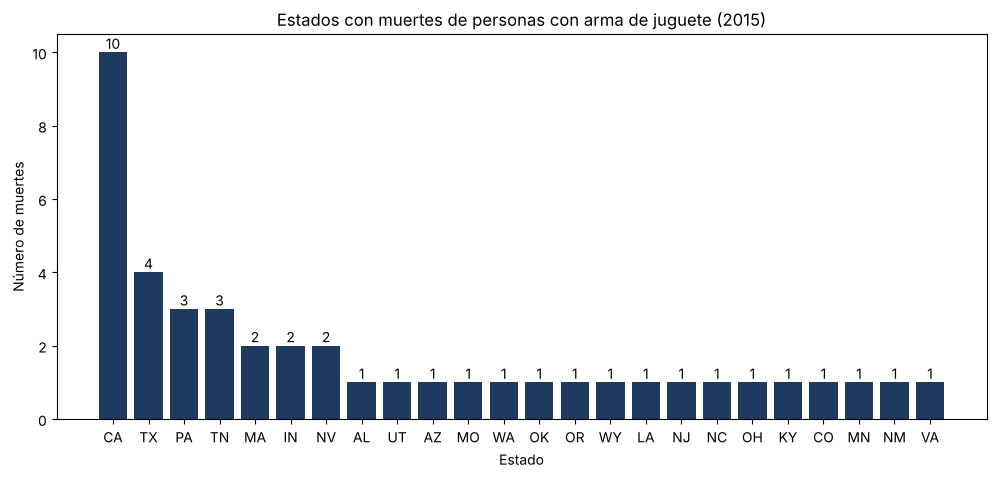

In [25]:
plt.figure(figsize=(12, 5))
plt.bar(juguete_estado.index, juguete_estado.values, color=AZUL)
for i in range(len(juguete_estado)):
    plt.text(i, juguete_estado.values[i] + 0.1, juguete_estado.values[i], ha='center')

plt.title('Estados con muertes de personas con arma de juguete (2015)')
plt.xlabel('Estado')
plt.ylabel('Número de muertes')
plt.show()

**Conclusión:** Hubo 43 muertes de personas que tenían un arma de juguete, en 24 estados diferentes. California tiene más casos (10), luego Texas (4), Pensilvania y Tennessee (3 cada uno). En la mayoría de los otros estados solo hubo un caso. Son pocos casos, pero importan porque la persona no tenía un arma real.

## Pregunta 5
### Para hombres blancos de entre 25 y 40 años, ¿qué estados registraron más muertes por tiroteos policiales?

Filtro: `gender` = M, `race` = W y edad entre 25 y 40 (se incluyen 25 y 40).

In [26]:
hombres_blancos = muertes_2015[(muertes_2015['gender'] == 'M') &
                               (muertes_2015['race'] == 'W') &
                               (muertes_2015['age'] >= 25) &
                               (muertes_2015['age'] <= 40)]

print('Total:', len(hombres_blancos))
hombres_blancos_estado = hombres_blancos['state'].value_counts()
print(hombres_blancos_estado.head(10))

Total: 192
state
CA    27
TX    14
AZ    10
FL    10
GA     8
OK     8
WA     6
MO     5
TN     5
OR     5
Name: count, dtype: int64


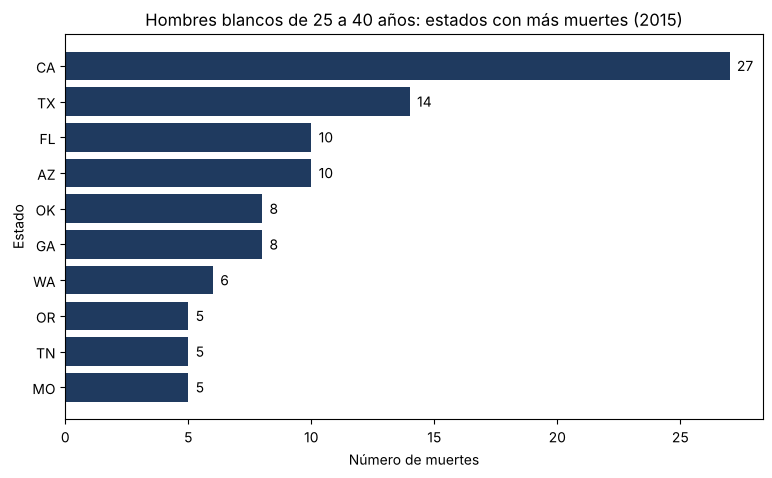

In [27]:
datos = hombres_blancos_estado.head(10).sort_values()

plt.figure(figsize=(9, 5))
plt.barh(datos.index, datos.values, color=AZUL)
for i in range(len(datos)):
    plt.text(datos.values[i] + 0.3, i, datos.values[i], va='center')

plt.title('Hombres blancos de 25 a 40 años: estados con más muertes (2015)')
plt.xlabel('Número de muertes')
plt.ylabel('Estado')
plt.show()

**Conclusión:** Murieron 192 hombres blancos de 25 a 40 años. California tiene más casos (27), luego Texas (14), Arizona y Florida (10 cada uno), Georgia y Oklahoma (8 cada uno). Pero esto es un conteo: California y Texas tienen mucha más gente que otros estados, por eso más adelante se calcula la tasa por población.

## Pregunta 6
### Para mujeres negras de entre 25 y 40 años, ¿qué estados registraron más muertes por tiroteos policiales?

Filtro: `gender` = F, `race` = B y edad entre 25 y 40.

In [28]:
mujeres_negras = muertes_2015[(muertes_2015['gender'] == 'F') &
                              (muertes_2015['race'] == 'B') &
                              (muertes_2015['age'] >= 25) &
                              (muertes_2015['age'] <= 40)]

print('Total:', len(mujeres_negras))
mujeres_negras_estado = mujeres_negras['state'].value_counts()
print(mujeres_negras_estado)

Total: 6
state
CA    3
MD    1
GA    1
VA    1
Name: count, dtype: int64


In [29]:
# como son pocos casos se pueden ver todos
mujeres_negras[['name', 'age', 'city', 'state', 'armed']]

,name,age,city,state,armed
80,Yuvette Henderson,38.0,Emeryville,CA,gun
235,Megan Hockaday,26.0,Oxnard,CA,knife
244,Mya Hall,27.0,Fort Meade,MD,vehicle
324,Alexia Christian,25.0,Atlanta,GA,gun
605,Redel Jones,30.0,Los Angeles,CA,knife
676,India Kager,28.0,Virginia Beach,VA,unarmed


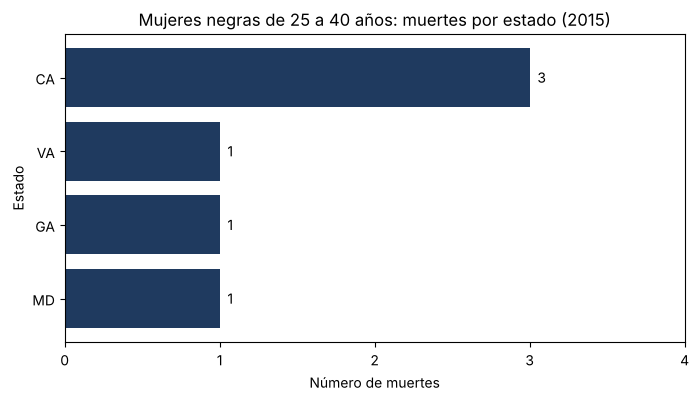

In [30]:
datos = mujeres_negras_estado.sort_values()

plt.figure(figsize=(8, 4))
plt.barh(datos.index, datos.values, color=AZUL)
for i in range(len(datos)):
    plt.text(datos.values[i] + 0.05, i, datos.values[i], va='center')

plt.title('Mujeres negras de 25 a 40 años: muertes por estado (2015)')
plt.xlabel('Número de muertes')
plt.ylabel('Estado')
plt.xticks([0, 1, 2, 3, 4])
plt.show()

**Conclusión:** Solo hay 6 casos: 3 en California y 1 en Georgia, Maryland y Virginia. California sale primero otra vez, pero con tan pocos casos no se puede decir mucho, porque un caso más o menos cambia el orden. En general las mujeres son muy pocas en los datos (42 de 991).

## Análisis complementario

### Muertes por estado y tasa por población

Comparar solo el número de muertes no es justo porque los estados tienen diferente población. Por eso se calcula:

tasa = muertes / población * 1,000,000  (muertes por cada millón de habitantes)

El archivo de población no tiene a Washington D.C., así que D.C. (4 muertes) no entra aquí. Rhode Island no tuvo muertes en 2015 y queda con 0.

In [31]:
poblacion['poblacion'] = poblacion['2015 population'].str.replace(',', '').astype(int)
poblacion = poblacion.rename(columns={'ID State': 'state'})

muertes_estado = muertes_2015['state'].value_counts().reset_index()
muertes_estado.columns = ['state', 'muertes']

tasas = pd.merge(poblacion[['state', 'poblacion']], muertes_estado, on='state', how='left')
tasas['muertes'] = tasas['muertes'].fillna(0).astype(int)
tasas['tasa'] = round(tasas['muertes'] / tasas['poblacion'] * 1000000, 2)

tasa_nacional = tasas['muertes'].sum() / tasas['poblacion'].sum() * 1000000
print('Tasa nacional:', round(tasa_nacional, 2))

Tasa nacional: 3.08


In [32]:
por_muertes = tasas.sort_values('muertes', ascending=False)
por_tasa = tasas.sort_values('tasa', ascending=False)

print(por_tasa.head(10))
print()
print(por_tasa[por_tasa['state'] == 'CA'])

   state  poblacion  muertes   tasa
49    WY     586107        6  10.24
30    NM    2085109       20   9.59
35    OK    3911338       32   8.18
27    NV    2890845       19   6.57
2     AZ    6828065       42   6.15
17    LA    4649676       27   5.81
1     AK     738432        4   5.42
47    WV    1844128       10   5.42
5     CO    5456574       29   5.31
4     CA   39144818      189   4.83

  state  poblacion  muertes  tasa
4    CA   39144818      189  4.83


In [33]:
# lugar de California en la tabla ordenada por tasa
lugar = list(por_tasa['state']).index('CA') + 1
print('California está en el lugar', lugar, 'de', len(por_tasa))

California está en el lugar 10 de 50


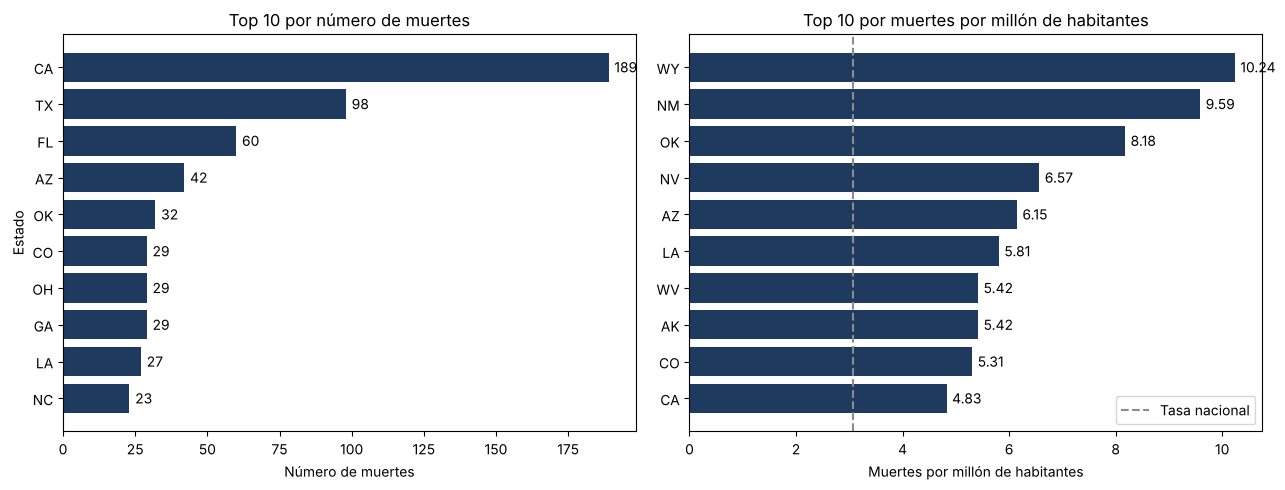

In [34]:
plt.figure(figsize=(13, 5))

datos1 = por_muertes.head(10).sort_values('muertes')
plt.subplot(1, 2, 1)
plt.barh(datos1['state'], datos1['muertes'], color=AZUL)
for i in range(len(datos1)):
    plt.text(datos1['muertes'].values[i] + 2, i, datos1['muertes'].values[i], va='center')
plt.title('Top 10 por número de muertes')
plt.xlabel('Número de muertes')
plt.ylabel('Estado')

datos2 = por_tasa.head(10).sort_values('tasa')
plt.subplot(1, 2, 2)
plt.barh(datos2['state'], datos2['tasa'], color=AZUL)
for i in range(len(datos2)):
    plt.text(datos2['tasa'].values[i] + 0.1, i, datos2['tasa'].values[i], va='center')
plt.axvline(tasa_nacional, color=GRIS, linestyle='--', label='Tasa nacional')
plt.title('Top 10 por muertes por millón de habitantes')
plt.xlabel('Muertes por millón de habitantes')
plt.legend(loc='lower right')

plt.tight_layout()
plt.show()

California tiene más muertes que cualquier otro estado (189), pero tiene 39 millones de habitantes. Su tasa es 4.83 muertes por millón y queda en el lugar 10 de 50. Los estados con tasa más alta son Wyoming (10.24), Nuevo México (9.59) y Oklahoma (8.18). La tasa de todo el país es 3.08. Wyoming solo tuvo 6 muertes, pero como tiene poca población su tasa sale alta.

### Comparación por raza

El archivo de raza da porcentajes por ciudad, pero no dice cuánta gente vive en cada ciudad. Para tener una idea de cuánta población hay de cada raza se hizo esto:

1. Promedio del porcentaje de cada raza en las ciudades de cada estado.
2. Ese porcentaje por la población del estado.
3. Sumar todos los estados.

Es solo una aproximación, porque un pueblo chico pesa igual que una ciudad grande. Además en el censo una persona hispana también se cuenta en su raza (blanca, negra, etc.), entonces los porcentajes no suman 100. Las 20 ciudades sin datos no se usan.

In [35]:
raza_estado = razas_ciudad.groupby('Geographic area')[['share_white', 'share_black', 'share_hispanic',
                                                       'share_asian', 'share_native_american']].mean()
raza_estado = raza_estado.reset_index().rename(columns={'Geographic area': 'state'})
raza_estado = pd.merge(raza_estado, poblacion[['state', 'poblacion']], on='state')

pob_blanca = (raza_estado['share_white'] / 100 * raza_estado['poblacion']).sum()
pob_negra = (raza_estado['share_black'] / 100 * raza_estado['poblacion']).sum()
pob_hispana = (raza_estado['share_hispanic'] / 100 * raza_estado['poblacion']).sum()
pob_asiatica = (raza_estado['share_asian'] / 100 * raza_estado['poblacion']).sum()
pob_nativa = (raza_estado['share_native_american'] / 100 * raza_estado['poblacion']).sum()

print('Blanca:', round(pob_blanca))
print('Negra:', round(pob_negra))
print('Hispana:', round(pob_hispana))
print('Asiática:', round(pob_asiatica))
print('Nativo americana:', round(pob_nativa))

Blanca: 260744539
Negra: 24742061
Hispana: 40437400
Asiática: 6748970
Nativo americana: 6482850


In [36]:
# víctimas por raza en los 50 estados (sin D.C. para que coincida con la población)
victimas = muertes_2015[muertes_2015['state'] != 'DC']
victimas_raza = victimas['race'].value_counts()
print(victimas_raza)

race
W     495
B     254
H     172
NA     28
O      15
A      14
N       9
Name: count, dtype: int64


In [37]:
total_victimas = victimas_raza.sum()
total_poblacion = poblacion['poblacion'].sum()

comparacion = pd.DataFrame({
    'victimas': [victimas_raza['W'], victimas_raza['B'], victimas_raza['H'], victimas_raza['A'], victimas_raza['NA']],
    'poblacion': [pob_blanca, pob_negra, pob_hispana, pob_asiatica, pob_nativa]},
    index=['Blanca', 'Negra', 'Hispana', 'Asiática', 'Nativo americana'])

comparacion['% víctimas'] = round(comparacion['victimas'] / total_victimas * 100, 1)
comparacion['% población'] = round(comparacion['poblacion'] / total_poblacion * 100, 1)
comparacion['tasa'] = round(comparacion['victimas'] / comparacion['poblacion'] * 1000000, 2)
comparacion

,victimas,poblacion,% víctimas,% población,tasa
Blanca,495,2.607445e+08,50.2,81.3,1.90
Negra,254,2.474206e+07,25.7,7.7,10.27
Hispana,172,4.043740e+07,17.4,12.6,4.25
Asiática,14,6.748970e+06,1.4,2.1,2.07
Nativo americana,28,6.482850e+06,2.8,2.0,4.32


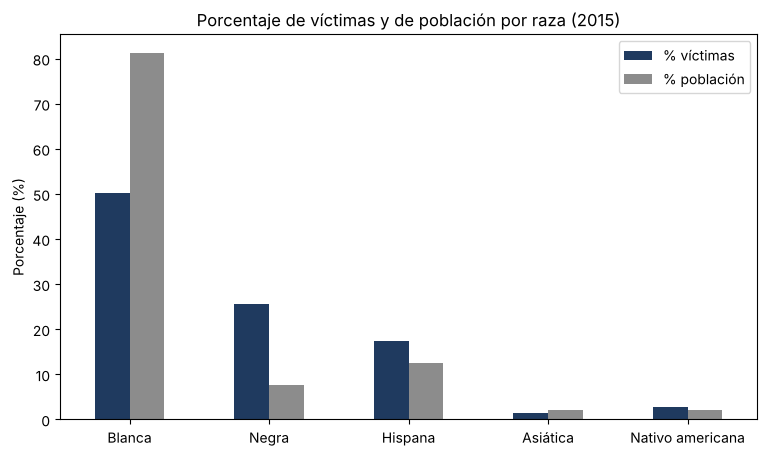

In [38]:
comparacion[['% víctimas', '% población']].plot(kind='bar', color=[AZUL, GRIS], figsize=(9, 5))
plt.title('Porcentaje de víctimas y de población por raza (2015)')
plt.ylabel('Porcentaje (%)')
plt.xlabel('')
plt.xticks(rotation=0)
plt.show()

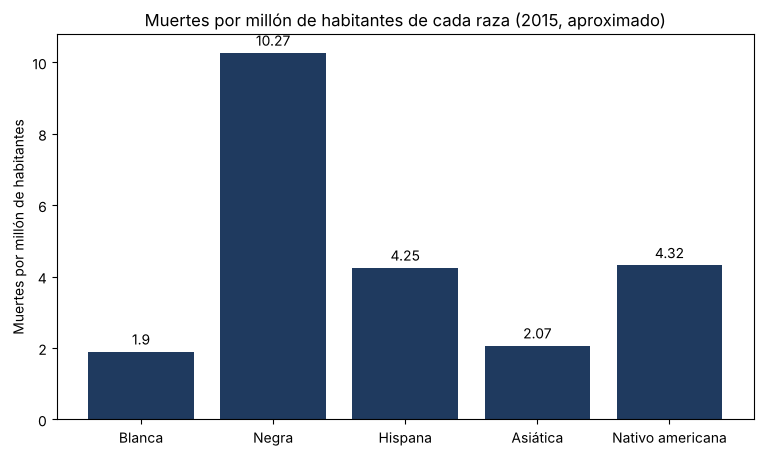

In [39]:
plt.figure(figsize=(9, 5))
plt.bar(comparacion.index, comparacion['tasa'], color=AZUL)
for i in range(len(comparacion)):
    plt.text(i, comparacion['tasa'].values[i] + 0.2, comparacion['tasa'].values[i], ha='center')

plt.title('Muertes por millón de habitantes de cada raza (2015, aproximado)')
plt.ylabel('Muertes por millón de habitantes')
plt.show()

Las personas blancas son el grupo con más víctimas (495, el 50.2%), pero son cerca del 81.3% de la población. Las personas negras son 254 víctimas (25.7%) y solo el 7.7% de la población. Por eso su tasa es de 10.27 muertes por millón, contra 1.90 de las personas blancas, más o menos 5.4 veces más. Hispanos (4.25) y nativo americanos (4.32) también tienen una tasa más alta que los blancos.

Hay que tener cuidado con dos cosas. En las víctimas, hispano es un grupo aparte, pero en la población un hispano también puede contar como blanco, entonces la población blanca puede estar inflada y la diferencia de 5.4 veces puede ser un poco menor en realidad. Y según `Races.csv`, NA es Native American, pero hay 28 casos con NA en 2015 y podrían ser datos faltantes.

### Pregunta opcional (no cuenta para la calificación)
### En los estados donde en promedio la población negra es más del 20%, ¿hay más muertes por tiroteo que en otros estados?

Se usa el promedio del porcentaje de población negra en las ciudades de cada estado y se compara la tasa por millón.

In [40]:
negra_estado = razas_ciudad.groupby('Geographic area')['share_black'].mean().round(1)
print(negra_estado[negra_estado > 20].sort_values(ascending=False))

Geographic area
DC    50.7
MS    41.8
SC    32.8
LA    30.8
GA    30.6
AL    23.3
NC    20.4
Name: share_black, dtype: float64


In [41]:
tasas = pd.merge(tasas, negra_estado, left_on='state', right_index=True)

mas_20 = tasas[tasas['share_black'] > 20]
resto = tasas[tasas['share_black'] <= 20]

tasa_mas_20 = mas_20['muertes'].sum() / mas_20['poblacion'].sum() * 1000000
tasa_resto = resto['muertes'].sum() / resto['poblacion'].sum() * 1000000

print('Estados con más de 20%:', len(mas_20), '- tasa:', round(tasa_mas_20, 2))
print('Resto de estados:', len(resto), '- tasa:', round(tasa_resto, 2))

Estados con más de 20%: 6 - tasa: 3.27
Resto de estados: 44 - tasa: 3.05


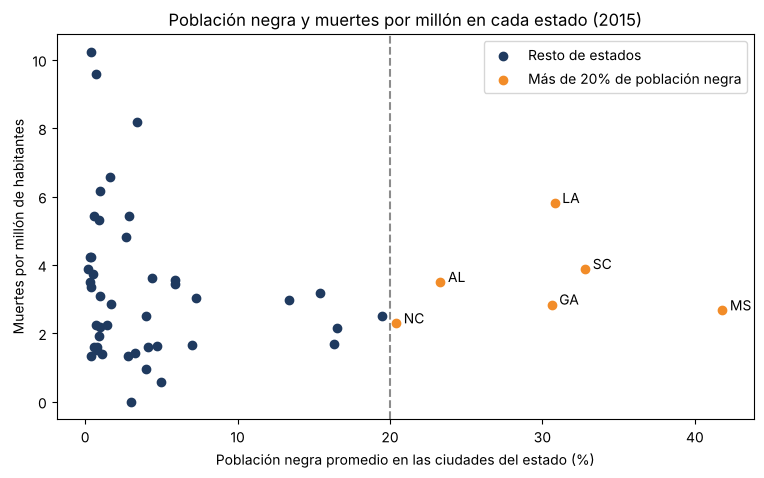

In [42]:
plt.figure(figsize=(9, 5))
plt.scatter(resto['share_black'], resto['tasa'], color=AZUL, label='Resto de estados')
plt.scatter(mas_20['share_black'], mas_20['tasa'], color=NARANJA, label='Más de 20% de población negra')
for i in range(len(mas_20)):
    plt.text(mas_20['share_black'].values[i] + 0.5, mas_20['tasa'].values[i], mas_20['state'].values[i])
plt.axvline(20, color=GRIS, linestyle='--')

plt.title('Población negra y muertes por millón en cada estado (2015)')
plt.xlabel('Población negra promedio en las ciudades del estado (%)')
plt.ylabel('Muertes por millón de habitantes')
plt.legend()
plt.show()

Los estados con más de 20% de población negra son Misisipi, Carolina del Sur, Luisiana, Georgia, Alabama y Carolina del Norte (D.C. también, pero no tiene población en el archivo). Su tasa es 3.27 por millón y la del resto es 3.05. Sí es un poco más alta, pero la diferencia es pequeña y viene sobre todo de Luisiana (5.81). Carolina del Norte (2.29) y Misisipi (2.67) están abajo del promedio, y los estados con tasa más alta (Wyoming, Nuevo México, Oklahoma) tienen muy poca población negra. No se ve una relación clara.

## Conclusiones

### ¿California es el estado donde es más probable morir en un tiroteo policial?

No. California tiene el mayor número de muertes (189) y la mayor cantidad de ciudades con casos (114), pero también es el estado con más habitantes. Con la tasa por millón queda en el lugar 10 (4.83). Los estados con más probabilidad son Wyoming (10.24), Nuevo México (9.59) y Oklahoma (8.18). Tener más muertes no quiere decir que sea más probable morir ahí.

### ¿Los resultados indican un sesgo racial?

Hay una diferencia grande entre razas: las personas negras son el 25.7% de las víctimas pero solo el 7.7% de la población, y su tasa es unas 5.4 veces la de las personas blancas. Esto es un indicio que vale la pena investigar.

Pero con estos datos no se puede asegurar que la causa sea racismo. No sabemos cuántas veces cada grupo tuvo contacto con la policía, qué pasó en cada caso, ni otros factores como pobreza o criminalidad en cada zona. Además, comparar estados con mucha población negra contra el resto no muestra una diferencia clara (3.27 contra 3.05). Lo que se puede decir es que hay una disparidad que se tendría que revisar, por ejemplo viendo la raza de las personas desarmadas (94) o con arma de juguete (43).

### Limitaciones

- Solo se usó 2015 (991 muertes).
- Ingresos y raza vienen por ciudad, no por estado, y no se sabe el tamaño de cada ciudad. Los promedios son aproximados.
- En la pregunta 2 se unieron 126 de 143 casos. En la tabla de ingresos 1,913 ciudades no tienen dato y `250,000+` se tomó como 250000.
- No hay población de Washington D.C.
- Algunos grupos tienen muy pocos casos (6 mujeres negras de 25 a 40 años), así que esos resultados pueden cambiar mucho.
- Los códigos de raza NA y N se tomaron como dice `Races.csv`.
- No se usaron datos de fuera.